In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Question 6.1

In [3]:
density_ref = 1000 #kg / m^3

P_surface = 101325 #Pa

z = np.array([-1000,-5000]) #m
g = 9.81

In [4]:
def P_z(z):
    return (P_surface - g*density_ref * z) / 101325

for solution, height in zip(P_z(z),z):
    print(f"At a depth of {-height} meters we get a pressure of {solution:.2f} atm.")

At a depth of 1000 meters we get a pressure of 97.82 atm.
At a depth of 5000 meters we get a pressure of 485.09 atm.


As we can see from the answer, pressure increases linearly with depth, as it increases with pressure around 100 atm per kilometer depth.

## Question 6.2

In [5]:
flux = 25 # W/m^2
dz = -50 # m 
dT = 1 # °C
density_fresh = 0.999e3 # Pa

def calc_dt(flux = flux,dz = dz, dT = dT,density = density_fresh):
    cw = 4.18e3

    # From the sensible heat flux equation:
    wT = flux / (density_fresh * cw) 
    dt = - (dz*dT) / (wT) 
    return dt # seconds

dt = calc_dt()

print(f"It takes {(dt / (3600*24)):.2f} days to increase the temperature by {dT} °C")

It takes 96.66 days to increase the temperature by 1 °C


In [6]:
# ???? oula had the answer

## Question 7.1

### a
Just use:

$$
p(z) = p_s + \int^\mu_z g \rho dz = p_s + g \rho_{ref} (\mu-z)
$$

and the add the latitude dependant function for mu (or whatever it's called):

$$
p(y,z)= p_s + g\rho_{ref}(\mu(y)-z)
$$

### b


Use:
$$
\frac{\partial p}{\partial y} = -fu\rho_{ref}
$$
and

$$
\frac{\partial}{\partial y} p(y,z)= \frac{\partial }{\partial y}(p_s + g\rho_{ref}(\mu(z)-z)) = g \rho_{ref}S
$$

Where $S$ is the slope of $\mu(y)$, which we can determine by:

$$
S = \arctan(\frac{\mu_m}{\theta_{mid}-\theta_{min}})
$$

In our situation, $S<0$. We can say that the first two equations are equal to each other and rewrite them for $u$, which is the value we want to know:

$$
-fu\rho_{ref} = g \rho_{ref}S
$$

$$
u = -\frac{g}{fS}
$$

In [7]:
# C

nu_m = 0.1
sigma_min = 50
sigma_mid = 40

S = np.arctan(nu_m/(sigma_mid-sigma_min)/(111000)) #slope

f = 1e-4

u = -9.81/f*S
print(f"The geostrophic current is equal to {u:.3E} m/s")

The geostrophic current is equal to 8.838E-03 m/s


# Question 8.1

In [10]:
diffusivity = 1e-5
z = -1e3
 
veloc = -40

time = z/veloc
print(f"It takes {time} years for a particle with velocity {veloc} m/year to a parth of {z} meters")

It takes 25.0 years for a particle with velocity -40 m/year to a parth of -1000.0 meters


# Question 8.2

In [53]:
def tau_theta_solution(r,theta):
    return 1/r*np.exp(-r/theta)

R = 10
r_array = np.arange(0,R+1,0.01)

theta_array = np.radians(np.arange(0, 361,1))

stress_matrix = np.zeros((len(theta_array),len(r_array)))
rmesh,thetamesh = np.meshgrid(r_array,theta_array)

stress_matrix = tau_theta_solution(rmesh,thetamesh)

/var/folders/k9/db40v6y15jq4qmgtynngdxrm0000gn/T/ipykernel_2315/1257942330.py:2: RuntimeWarning: divide by zero encountered in divide
  return 1/r*np.exp(-r/theta)
/var/folders/k9/db40v6y15jq4qmgtynngdxrm0000gn/T/ipykernel_2315/1257942330.py:2: RuntimeWarning: invalid value encountered in divide
  return 1/r*np.exp(-r/theta)


In [70]:
stress_matrix[300]

array([           inf, 9.98091963e+01, 4.98093784e+01, ...,
       1.12175031e-02, 1.11859029e-02, 1.11544009e-02], shape=(1100,))

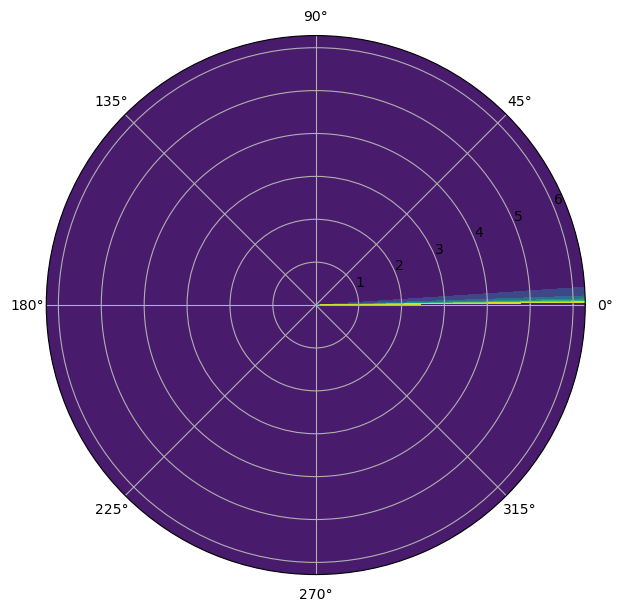

In [69]:
plt.figure(figsize=(10,7))
plt.axes(projection='polar')

plt.contourf(rmesh,thetamesh,stress_matrix)

# 8.3

In [ ]:
Ly=5e6
density_ref = 1000
tau_s = 0.1

def beta(phi):
    omega = 7.29e-5
    a = 6371e3
    return 2 * omega * a *np.cos(phi)

b = beta(np.deg2rad(35))

V = 1/b * (tau_s*np.pi)/(density_ref*Ly)*np.sin(np.pi * )